In [52]:
import numpy as np 
import pandas as pd 
import seaborn as sns 

## **Exercise: Imbalance Classification**

**Gunakan dataset 'stroke.csv'**

Carilah model dan hyperparameter terbaik untuk memprediksi apakah seorang pasien menderita stroke.

1. Lakukan EDA untuk memahami dataset.
1. Lakukan preprocessing pada features jika dibutuhkan.
1. Lakukan modeling dengan menggunakan logistic regression, knn, dan decision tree.<br>
    Kandidat algoritma:
    - logreg = LogisticRegression(solver='liblinear', random_state=0)
    - knn = KNeighborsClassifier(n_neighbors=5)
    - tree = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=1, max_depth=5, random_state=0)
1. Pilih 1 model terbaik berdasarkan hasil cross validasi 3 model di atas. Tentukan model benchmark-nya dengan melakukan imbalanced data treatment (bisa menggunakan SMOTE atau yang lainnya).
1. Lakukan hyperparameter tuning pada model terpilih tsb.
1. Lakukan prediksi pada test set dari model benchmark (sebelum hyperparameter tuning).
1. Lakukan prediksi pada test set dari model dengan hyperparameter tuning.
1. Bandingkan hasil performa model sebelum dan sesudah tuning.

## **Feature Information**

- id: unique identifier
- gender: "Male", "Female" or "Other"
- age: age of the patient
- hypertension: 0 if the patient doesn't have hypertension, 1 if the patient has hypertension
- heart_disease: 0 if the patient doesn't have any heart diseases, 1 if the patient has a heart disease
- ever_married: "No" or "Yes"
- work_type: "children", "Govt_jov", "Never_worked", "Private" or "Self-employed"
- Residence_type: "Rural" or "Urban"
- avg_glucose_level: average glucose level in blood
- bmi: body mass index
-smoking_status: "formerly smoked", "never smoked", "smokes" or "Unknown"
- stroke: 1 if the patient had a stroke or 0 if not *Note: "Unknown" in smoking_status means that the information is unavailable for this patient

# EDA

In [53]:
stroke = pd.read_csv('../Dataset/stroke.csv')

In [54]:
stroke.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [55]:
stroke.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [66]:
stroke.drop(['id'], inplace=True,axis =1)

In [78]:
# Memeriksa outliers pada fitur numerik
print("\nOutliers pada Fitur Numerik:")
numerical_features = stroke.drop('stroke', axis=1).select_dtypes(include=['int64', 'float64']).columns
for feature in numerical_features:
    Q1 = stroke[feature].quantile(0.25)
    Q3 = stroke[feature].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = stroke[(stroke[feature] < lower_bound) | (stroke[feature] > upper_bound)][feature]
    print(f"Outliers pada fitur '{feature}': {len(outliers)}")



Outliers pada Fitur Numerik:
Outliers pada fitur 'age': 0
Outliers pada fitur 'hypertension': 498
Outliers pada fitur 'heart_disease': 276
Outliers pada fitur 'avg_glucose_level': 627
Outliers pada fitur 'bmi': 126


In [79]:
stroke.fillna(stroke['bmi'].median(), inplace=True)

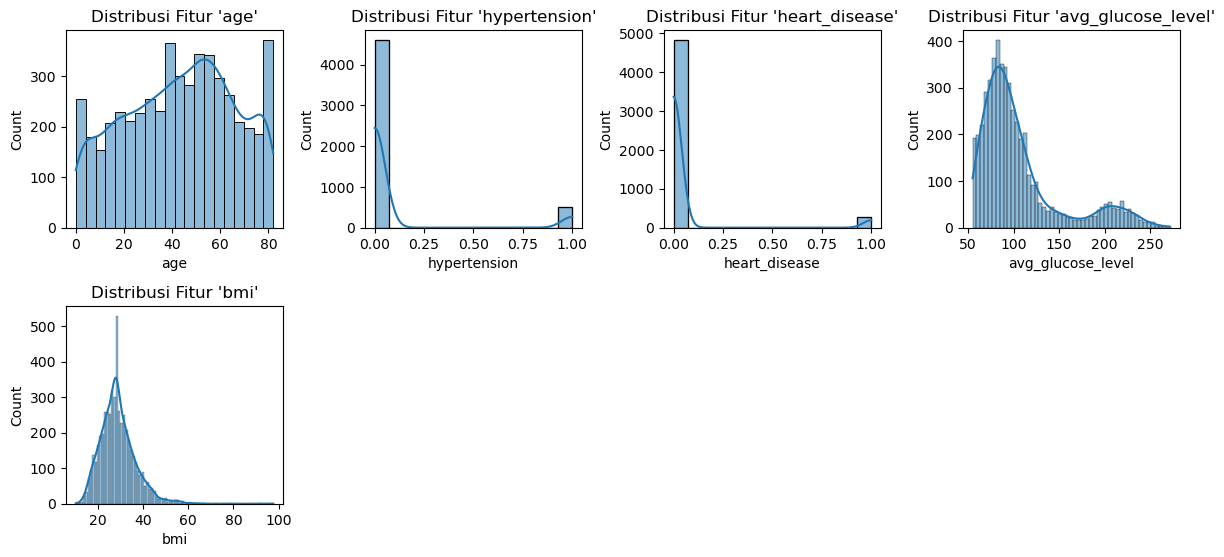

In [80]:
import matplotlib.pyplot as plt
# Visualisasi fitur numerik
plt.figure(figsize=(12, 8))
for i, feature in enumerate(numerical_features, 1):
    plt.subplot(3, 4, i)
    sns.histplot(data=stroke, x=feature, kde=True)
    plt.title(f"Distribusi Fitur '{feature}'")
plt.tight_layout()
plt.show()

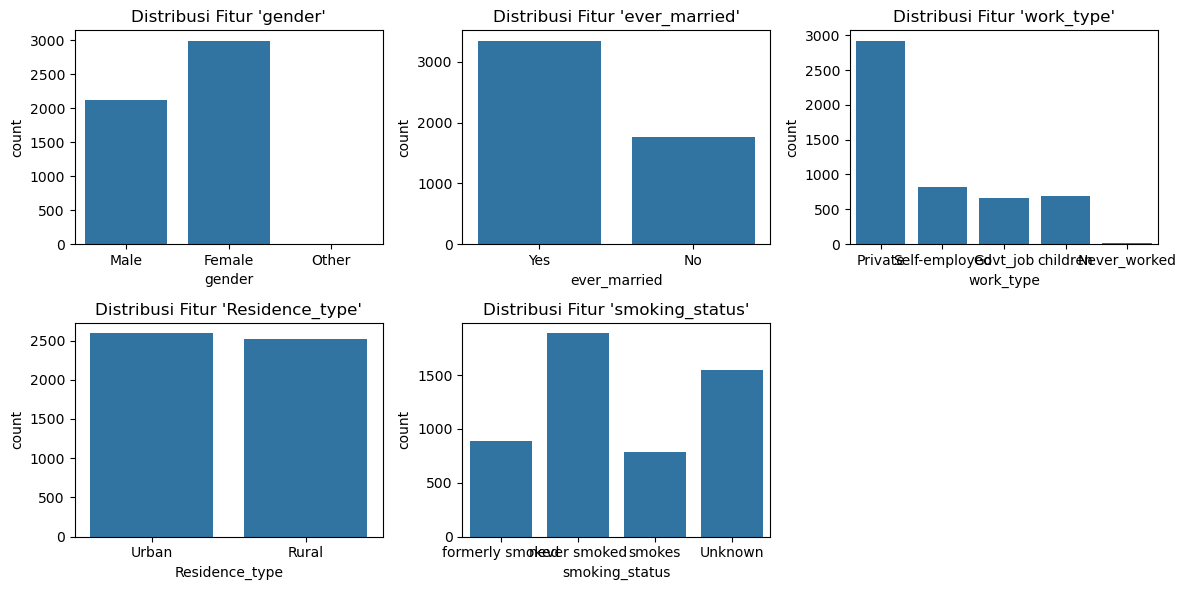

In [81]:
# Visualisasi fitur kategorik
categorical_features = stroke.select_dtypes(include=['object']).columns
plt.figure(figsize=(12, 6))
for i, feature in enumerate(categorical_features, 1):
    plt.subplot(2, 3, i)
    sns.countplot(data=stroke, x=feature)
    plt.title(f"Distribusi Fitur '{feature}'")
plt.tight_layout()
plt.show()

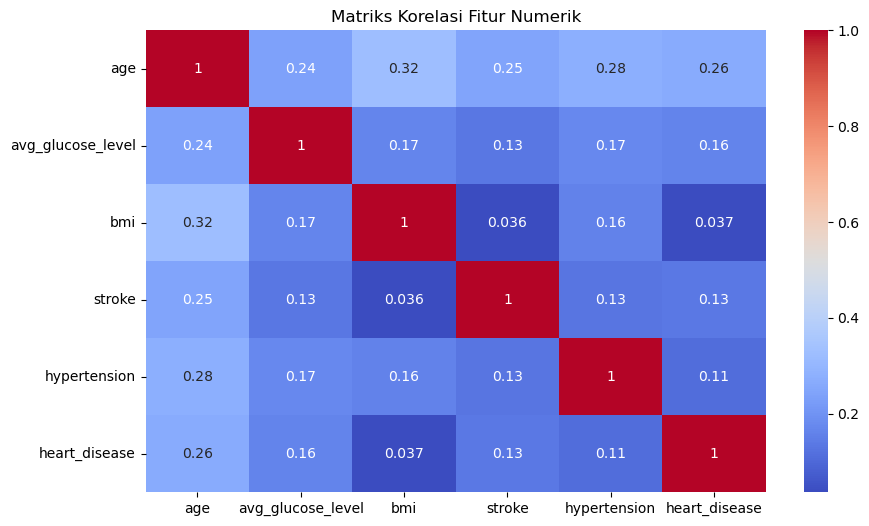

In [82]:
# Analisis korelasi antara fitur numerik dan target
stroke_num = stroke[['age','avg_glucose_level','bmi','stroke','hypertension','heart_disease']]

plt.figure(figsize=(10, 6))
sns.heatmap(stroke_num.corr(), annot=True, cmap='coolwarm')
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

# Preprocessing

In [83]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [84]:
X = stroke.drop(['stroke'], axis=1)
y = stroke['stroke']

In [85]:
# Numerical preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])



In [86]:
# Combine numeric and categorical pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Apply preprocessing
X_preprocessed = preprocessor.fit_transform(X)

# Modeling

In [87]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score, roc_auc_score

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=42)

# Import models
logreg = LogisticRegression(solver='liblinear', random_state=0)
knn = KNeighborsClassifier(n_neighbors=5)
tree = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=1, max_depth=5, random_state=0)

# Create a list of models
models = [logreg, knn, tree]

# Perform cross-validation and select the best model
best_model = None
best_score = 0

for model in models:
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')
    avg_score = cv_scores.mean()
    print(f"{model.__class__.__name__} AUC-ROC: {avg_score:.3f}")
    
    if avg_score > best_score:
        best_model = model
        best_score = avg_score

print(f"\nBest model: {best_model.__class__.__name__} with AUC-ROC: {best_score:.3f}")

LogisticRegression AUC-ROC: 0.838
KNeighborsClassifier AUC-ROC: 0.604
DecisionTreeClassifier AUC-ROC: 0.789

Best model: LogisticRegression with AUC-ROC: 0.838


In [90]:
stroke['stroke'].value_counts(normalize=True)

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64

# Imbalanced data treatment

In [92]:
from imblearn.over_sampling import SMOTE
from collections import Counter

# Check class distribution before oversampling
print("Class distribution before oversampling:")
print(Counter(y_train))

# Apply SMOTE oversampling
smote = SMOTE()
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

# Check class distribution after oversampling
print("\nClass distribution after oversampling:")
print(Counter(y_train_resampled))

# Fit the best model on the oversampled training data
best_model.fit(X_train_resampled, y_train_resampled)

Class distribution before oversampling:
Counter({0: 3901, 1: 187})

Class distribution after oversampling:
Counter({0: 3901, 1: 3901})


LogisticRegression(random_state=0, solver='liblinear')

# Hypereparameter tuning

In [93]:
from sklearn.model_selection import GridSearchCV

# Asumsi model terbaik adalah logistic regression
best_model = logreg

# Mendefinisikan parameter grid untuk logistic regression
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2']
}

# Membuat objek GridSearchCV
grid_search = GridSearchCV(estimator=best_model,
                           param_grid=param_grid,
                           scoring='roc_auc',
                           cv=5,
                           n_jobs=-1)

# Melakukan hyperparameter tuning
grid_search.fit(X_train_resampled, y_train_resampled)

# Mencetak hasil terbaik
print("Hyperparameter terbaik:", grid_search.best_params_)
print("Skor terbaik:", grid_search.best_score_)

# Evaluasi performa model dengan hyperparameter terbaik pada data validasi
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi pada data validasi:", best_model.score(X_test, y_test))

Hyperparameter terbaik: {'C': 100, 'penalty': 'l2'}
Skor terbaik: 0.8533649117224416
Akurasi pada data validasi: 0.7553816046966731


# Pediction and Evaluation metric

In [94]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Prediksi dengan model benchmark
y_pred_benchmark = best_model.predict(X_test)

# Fit the best model with the training data
best_model.fit(X_train, y_train)

# Predict using the best fit model
y_pred_best_fit = best_model.predict(X_test)

# Calculate accuracy
accuracy_benchmark = accuracy_score(y_test, y_pred_benchmark)
accuracy_best_fit = accuracy_score(y_test, y_pred_best_fit)
print("Accuracy (benchmark model):", accuracy_benchmark)
print("Accuracy (best fit)     : ", accuracy_best_fit)

# Print confusion matrix
print("Confusion matrix (benchmark model)")
print(confusion_matrix(y_test, y_pred_benchmark))
print("Confusion matrix (best fit model)")
print(confusion_matrix(y_test, y_pred_best_fit))

# Calculate other metrics
# ... (code for calculating other metrics)

Accuracy (benchmark model): 0.7553816046966731
Accuracy (best fit)     :  0.9393346379647749
Confusion matrix (benchmark model)
[[726 234]
 [ 16  46]]
Confusion matrix (best fit model)
[[960   0]
 [ 62   0]]
